# Mini-Projet Séries Temporelles — Partie 3
## Modélisation classique : ARIMA, VAR / Granger, cointégration de Johansen, ARCH / GARCH — AAPL & QQQ

Prérequis : avoir exécuté le notebook de la partie 1 (il écrit `dataset_partie1.csv` dans le même dossier).

In [ ]:
# === Reprise des données de la partie 1 ===============================================
# Ce notebook est autonome : il relit le jeu de données préparé dans la partie 1 (dataset_partie1.csv)
# et refait exactement le même découpage chronologique 90 % / 10 %.
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller, kpss

np.random.seed(42)

dataset = pd.read_csv("dataset_partie1.csv", index_col=0, parse_dates=True)
split_index = int(len(dataset) * 0.90)
train = dataset.iloc[:split_index].copy()
test = dataset.iloc[split_index:].copy()
print("Dataset :", dataset.shape, "| Train :", len(train), "| Test :", len(test))
print("Train jusqu'à :", train.index[-1])

## Modèle ARIMA - Identification des paramètres

In [57]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy.stats import jarque_bera

In [58]:
!pip install pmdarima

  Using cached pmdarima-2.1.1-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (8.5 kB)
Using cached pmdarima-2.1.1-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl (688 kB)


In [59]:
from pmdarima import auto_arima

arima_auto = auto_arima(
    train["AAPL"],
    seasonal=False,
    stepwise=True,
    suppress_warnings=True,
    error_action="ignore",
    trace=True
)

print(arima_auto.summary())

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=8558.390, Time=10.42 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=8555.036, Time=0.10 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=8556.486, Time=0.38 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=8556.508, Time=0.68 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=8557.075, Time=0.12 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=8559.011, Time=1.55 sec

Best model:  ARIMA(0,1,0)(0,0,0)[0] intercept
Total fit time: 13.302 seconds
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 1752
Model:               SARIMAX(0, 1, 0)   Log Likelihood               -4275.518
Date:                Sun, 11 Oct 2026   AIC                           8555.036
Time:                        23:10:54   BIC                           8565.971
Sample:                             0   HQIC                          8559.078
        

In [60]:
print("Ordre ARIMA choisi :", arima_auto.order)

Ordre ARIMA choisi : (0, 1, 0)


## Estimation du modèle ARIMA

In [61]:
p, d, q = arima_auto.order

model_arima = ARIMA(
    train["AAPL"],
    order=(p, d, q)
)

arima_result = model_arima.fit()

print(arima_result.summary())

                               SARIMAX Results                                
Dep. Variable:                   AAPL   No. Observations:                 1752
Model:                 ARIMA(0, 1, 0)   Log Likelihood               -4277.537
Date:                Sun, 11 Oct 2026   AIC                           8557.075
Time:                        23:10:54   BIC                           8562.543
Sample:                             0   HQIC                          8559.096
                               - 1752                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sigma2         7.7519      0.115     67.405      0.000       7.527       7.977
Ljung-Box (L1) (Q):                   0.55   Jarque-Bera (JB):              5140.82
Prob(Q):                              0.46   Pr

## Diagnostic des résidus ARIMA

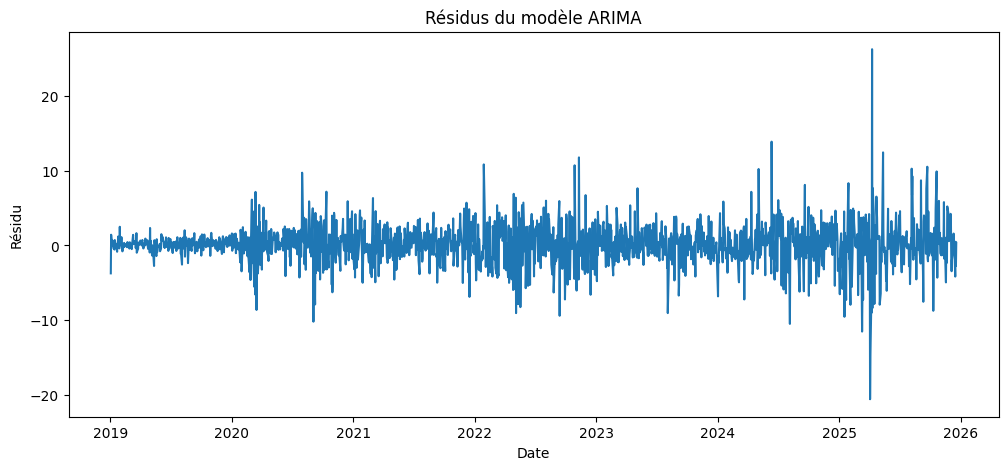

In [62]:
residuals_arima = arima_result.resid.iloc[1:].dropna()

plt.figure(figsize=(12, 5))
plt.plot(residuals_arima)
plt.title("Résidus du modèle ARIMA")
plt.xlabel("Date")
plt.ylabel("Résidu")
plt.show()

In [63]:
#test de Ljung-Box
ljung_box = acorr_ljungbox(
    residuals_arima.dropna(),
    lags=[10, 20],
    return_df=True
)

print(ljung_box)

      lb_stat  lb_pvalue
10  17.419893   0.065574
20  29.966659   0.070396


In [64]:
#Normalité des résidus
jb_stat, jb_pvalue = jarque_bera(residuals_arima.dropna())

print("Jarque-Bera statistic :", jb_stat)
print("p-value :", jb_pvalue)

Jarque-Bera statistic : 5140.81862602731
p-value : 0.0


In [65]:
#ARCH-LM
#vérifier l'hétéroscédasticité.
from statsmodels.stats.diagnostic import het_arch

In [66]:
arch_test = het_arch(residuals_arima.dropna())

print("ARCH-LM statistic :", arch_test[0])
print("p-value :", arch_test[1])

ARCH-LM statistic : 257.96660537155265
p-value : 1.144875361627634e-49


## Modèle VAR - AAPL et QQQ

In [67]:
from statsmodels.tsa.api import VAR

In [68]:
var_data = train[["AAPL_Return", "QQQ_Return"]].dropna()

print(var_data.head())
print(var_data.shape)

            AAPL_Return  QQQ_Return
Date                               
2019-01-03    -0.104924   -0.033216
2019-01-04     0.041803    0.041894
2019-01-07    -0.002228    0.011836
2019-01-08     0.018884    0.009005
2019-01-09     0.016839    0.008116
(1751, 2)


In [69]:
var_model = VAR(var_data)

lag_selection = var_model.select_order(maxlags=20)

print(lag_selection.summary())

 VAR Order Selection (* highlights the minimums)  
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0       -17.37      -17.36   2.872e-08      -17.36
1       -17.38     -17.36*   2.820e-08     -17.38*
2       -17.38      -17.35   2.819e-08      -17.37
3       -17.39      -17.34   2.817e-08      -17.37
4       -17.39      -17.33   2.813e-08      -17.37
5       -17.38      -17.32   2.817e-08      -17.36
6       -17.38      -17.30   2.820e-08      -17.35
7       -17.39      -17.29   2.808e-08      -17.35
8       -17.39      -17.28   2.806e-08      -17.35
9      -17.40*      -17.28  2.779e-08*      -17.35
10      -17.40      -17.26   2.788e-08      -17.35
11      -17.39      -17.25   2.798e-08      -17.34
12      -17.39      -17.23   2.808e-08      -17.33
13      -17.39      -17.22   2.813e-08      -17.32
14      -17.38      -17.20   2.825e-08      -17.31
15      -17.38      -17.18   2.834e-08      -17.31
16      -17.38      -17.17   2.

In [70]:
print("Lag choisi par AIC :", lag_selection.aic)
print("Lag choisi par BIC :", lag_selection.bic)
print("Lag choisi par HQIC :", lag_selection.hqic)

Lag choisi par AIC : 9
Lag choisi par BIC : 1
Lag choisi par HQIC : 1


In [71]:
var_result = var_model.fit(lag_selection.aic)

print(var_result.summary())

  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Sun, 11, Oct, 2026
Time:                     23:10:55
--------------------------------------------------------------------
No. of Equations:         2.00000    BIC:                   -17.2761
Nobs:                     1742.00    HQIC:                  -17.3512
Log likelihood:           10245.7    FPE:                2.78834e-08
AIC:                     -17.3952    Det(Omega_mle):     2.72850e-08
--------------------------------------------------------------------
Results for equation AAPL_Return
                    coefficient       std. error           t-stat            prob
---------------------------------------------------------------------------------
const                  0.001204         0.000467            2.577           0.010
L1.AAPL_Return         0.011504         0.041630            0.276           0.782
L1.QQQ_Return         -0.106178         0.053164  

In [72]:
print("Stabilité du VAR :", var_result.is_stable())

Stabilité du VAR : True


In [73]:
granger_aapl_qqq = var_result.test_causality(
    "QQQ_Return",
    ["AAPL_Return"],
    kind="f"
)

print(granger_aapl_qqq.summary())

Granger causality F-test. H_0: AAPL_Return does not Granger-cause QQQ_Return. Conclusion: fail to reject H_0 at 5% significance level.
Test statistic Critical value p-value          df        
---------------------------------------------------------
         1.096          1.883   0.362 (9, np.int64(3446))
---------------------------------------------------------


In [74]:
granger_qqq_aapl = var_result.test_causality(
    "AAPL_Return",
    ["QQQ_Return"],
    kind="f"
)

print(granger_qqq_aapl.summary())

Granger causality F-test. H_0: QQQ_Return does not Granger-cause AAPL_Return. Conclusion: reject H_0 at 5% significance level.
Test statistic Critical value p-value          df        
---------------------------------------------------------
         3.109          1.883   0.001 (9, np.int64(3446))
---------------------------------------------------------


## Cointegration

In [75]:
from statsmodels.tsa.vector_ar.vecm import coint_johansen

In [76]:
log_prices = np.log(train[["AAPL", "QQQ"]].dropna())

johansen_result = coint_johansen(
    log_prices,
    det_order=0,
    k_ar_diff=1
)

print("Trace statistics :")
print(johansen_result.lr1)

print("\nCritical values à 5 % :")
print(johansen_result.cvt[:, 1])

Trace statistics :
[10.85526803  0.48521429]

Critical values à 5 % :
[15.4943  3.8415]


## ARCH / GARCH

In [77]:
from arch import arch_model

In [78]:
returns_aapl = train["AAPL_Return"].dropna() * 100

garch_model = arch_model(
    returns_aapl,
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1
)

garch_result = garch_model.fit(disp="off")

print(garch_result.summary())

                     Constant Mean - GARCH Model Results                      
Dep. Variable:            AAPL_Return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -3460.85
Distribution:                  Normal   AIC:                           6929.70
Method:            Maximum Likelihood   BIC:                           6951.57
                                        No. Observations:                 1751
Date:                Sun, Oct 11 2026   Df Residuals:                     1750
Time:                        23:11:00   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.1753  4.105e-02      4.271  1.943e-05 [9.487e-0

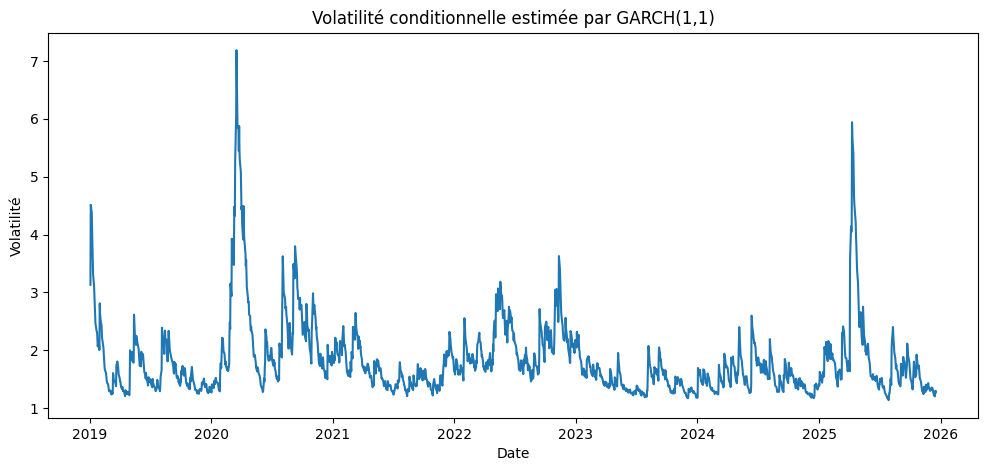

In [79]:
plt.figure(figsize=(12, 5))

plt.plot(
    garch_result.conditional_volatility
)

plt.title("Volatilité conditionnelle estimée par GARCH(1,1)")
plt.xlabel("Date")
plt.ylabel("Volatilité")

plt.show()

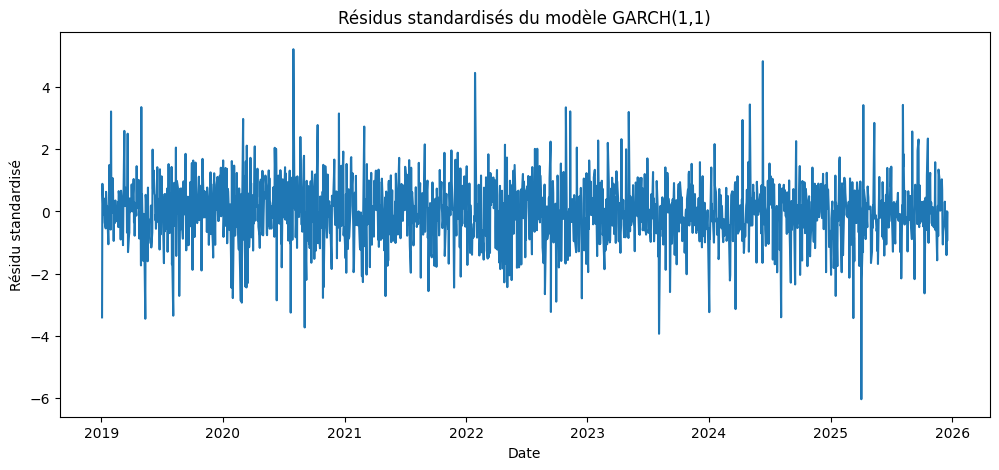

In [80]:
standardized_residuals = garch_result.std_resid.dropna()

plt.figure(figsize=(12, 5))

plt.plot(standardized_residuals)

plt.title("Résidus standardisés du modèle GARCH(1,1)")
plt.xlabel("Date")
plt.ylabel("Résidu standardisé")

plt.show()

In [81]:
lb_garch = acorr_ljungbox(
    standardized_residuals,
    lags=[10, 20],
    return_df=True
)

print(lb_garch)

      lb_stat  lb_pvalue
10   7.015641   0.723967
20  16.095493   0.710683


In [82]:
from statsmodels.stats.diagnostic import het_arch

arch_garch = het_arch(standardized_residuals)

print("ARCH-LM statistic :", arch_garch[0])
print("p-value :", arch_garch[1])

ARCH-LM statistic : 8.653642330758316
p-value : 0.5652589816405376


In [83]:
jb_garch = jarque_bera(standardized_residuals)

print("Jarque-Bera statistic :", jb_garch.statistic)
print("p-value :", jb_garch.pvalue)

Jarque-Bera statistic : 466.2970766946225
p-value : 5.557459826229279e-102
